In [2]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_ddm_posterior,
    load_ddm_subj_params,
    load_behavioral_data,
    DATASET_LABELS,
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
import statsmodels.api as sm

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
MODEL = "HDDM_Base_Lag1-stpdrift"
STP_DDM_MODEL = "HDDM_Base_Lag1-stp"
DRIFT_DDM_MODEL = "HDDM_Base_Lag1-drift"

manual_exclusions_drift = {
    "equalIndifference": [],
    "equalRange": [],
    "sheng2020": []
}

manual_exclusions_stp = {
    "equalIndifference": [],
    "equalRange": [58],
    "sheng2020": []
}

### Helper functions

In [3]:
BF_THRESHOLD_HIGH = 3
BF_THRESHOLD_LOW = 1 / 3

BF_COLORS = {
    "evidence_for":     "#017D01",
    "inconclusive":     "#B0B0B0",
    "evidence_against": "#6A51A3",
}


def bf_category(bf10):
    if bf10 > BF_THRESHOLD_HIGH:
        return "evidence_for"
    if bf10 < BF_THRESHOLD_LOW:
        return "evidence_against"
    return "inconclusive"


def spearman_corr_bf(x, y):
    """Spearman r/p (Pearson correlation computed on rank-transformed data,
    which is what Spearman's rho is by definition) plus the resulting JZS
    Bayes Factor (BF10), and an OLS line + 95% CI band fit on the raw
    (non-ranked) points for visual reference."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    rank_x = pd.Series(x).rank().values
    rank_y = pd.Series(y).rank().values

    res = pg.corr(rank_x, rank_y, method="pearson")
    r = float(res["r"].iloc[0])
    pval = float(res["p_val"].iloc[0])
    bf10 = float(res["BF10"].iloc[0])
    category = bf_category(bf10)

    ols_fit = sm.OLS(y, sm.add_constant(x)).fit()
    x_line = np.linspace(x.min(), x.max(), 100)
    pred = ols_fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)

    return {
        "r": r,
        "pval": pval,
        "bf10": bf10,
        "category": category,
        "n": len(x),
        "x_line": x_line,
        "y_line": pred["mean"].values,
        "ci_low": pred["mean_ci_lower"].values,
        "ci_high": pred["mean_ci_upper"].values,
    }


def style_axis(ax, col=None, ylabel=None, xlabel=None, xlabel_col=1):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0 and ylabel:
        ax.set_ylabel(ylabel)
    if col == xlabel_col and xlabel:
        ax.set_xlabel(xlabel)


def format_bf(bf10):
    # one decimal point
    return f"{np.log10(bf10):.1f}"


def format_pval(p):
    if p < 0.001:
        return "<.001"
    if p < 0.01:
        return "<.01"
    if p < 0.05:
        return "<.05"
    return "=n.s."


def plot_spearman_corr(ax, x, y):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    result = spearman_corr_bf(x, y)
    color = BF_COLORS[result["category"]]

    ax.scatter(x, y, color=color, alpha=0.75, edgecolor="black",
               linewidth=0.5, s=75, zorder=3)
    ax.fill_between(result["x_line"], result["ci_low"], result["ci_high"],
                     color=color, alpha=0.15, zorder=1)
    ax.plot(result["x_line"], result["y_line"], color=color, linewidth=1.5,
            linestyle="--", zorder=4)

    ax.text(0.05, 0.95,
            f"ρ = {result['r']:.2f}, p {format_pval(result['pval'])}\n"
            f"log10(BF10) = {format_bf(result['bf10'])}\nn = {result['n']}",
            transform=ax.transAxes, ha="left", va="top", fontsize=14,
            color=color, fontweight="bold")

    return result

## Figure S6
Row A: per-subject correlation between posterior draws of `v_choice_prev1` (fixed drift bias) and `z_choice_prev1` (starting-point bias) for the SP-Drift-CH model (`HDDM_Base_Lag1-stpdrift`), one histogram per dataset. For each subject, the correlation is computed within each MCMC chain and averaged across chains.

Row B: per-subject choice-history shift in the drift bias (`v_choice_prev1`, from `DRIFT_DDM_MODEL`) vs. the starting-point bias (`z_choice_prev1`, from `STP_DDM_MODEL`) -- each from its own single-mechanism model, not the combined model used in Row A. Subjects manually excluded from either parameter's own convergence check (union of `manual_exclusions_drift`/`manual_exclusions_stp`) are dropped.

In [4]:
behavioral_data = load_behavioral_data()

Individual shift in fixed drift (v_choice_prev1) vs. starting point (z_choice_prev1):
  equalIndifference: r = 0.73, p = 2.91e-10, log10(BF10) = 7.6, n = 54
  equalRange: r = 0.67, p = 4.31e-08, log10(BF10) = 5.6, n = 53
  sheng2020: r = 0.85, p = 1.16e-23, log10(BF10) = 20.6, n = 82

Per-subject/chain posterior-draw correlation:
  equalIndifference: mean = -0.333, sd = 0.054, n = 216
  equalIndifference: min = -0.480, max = -0.188
  equalRange: mean = -0.190, sd = 0.024, n = 216
  equalRange: min = -0.237, max = -0.102
  sheng2020: mean = -0.301, sd = 0.048, n = 328
  sheng2020: min = -0.445, max = -0.180


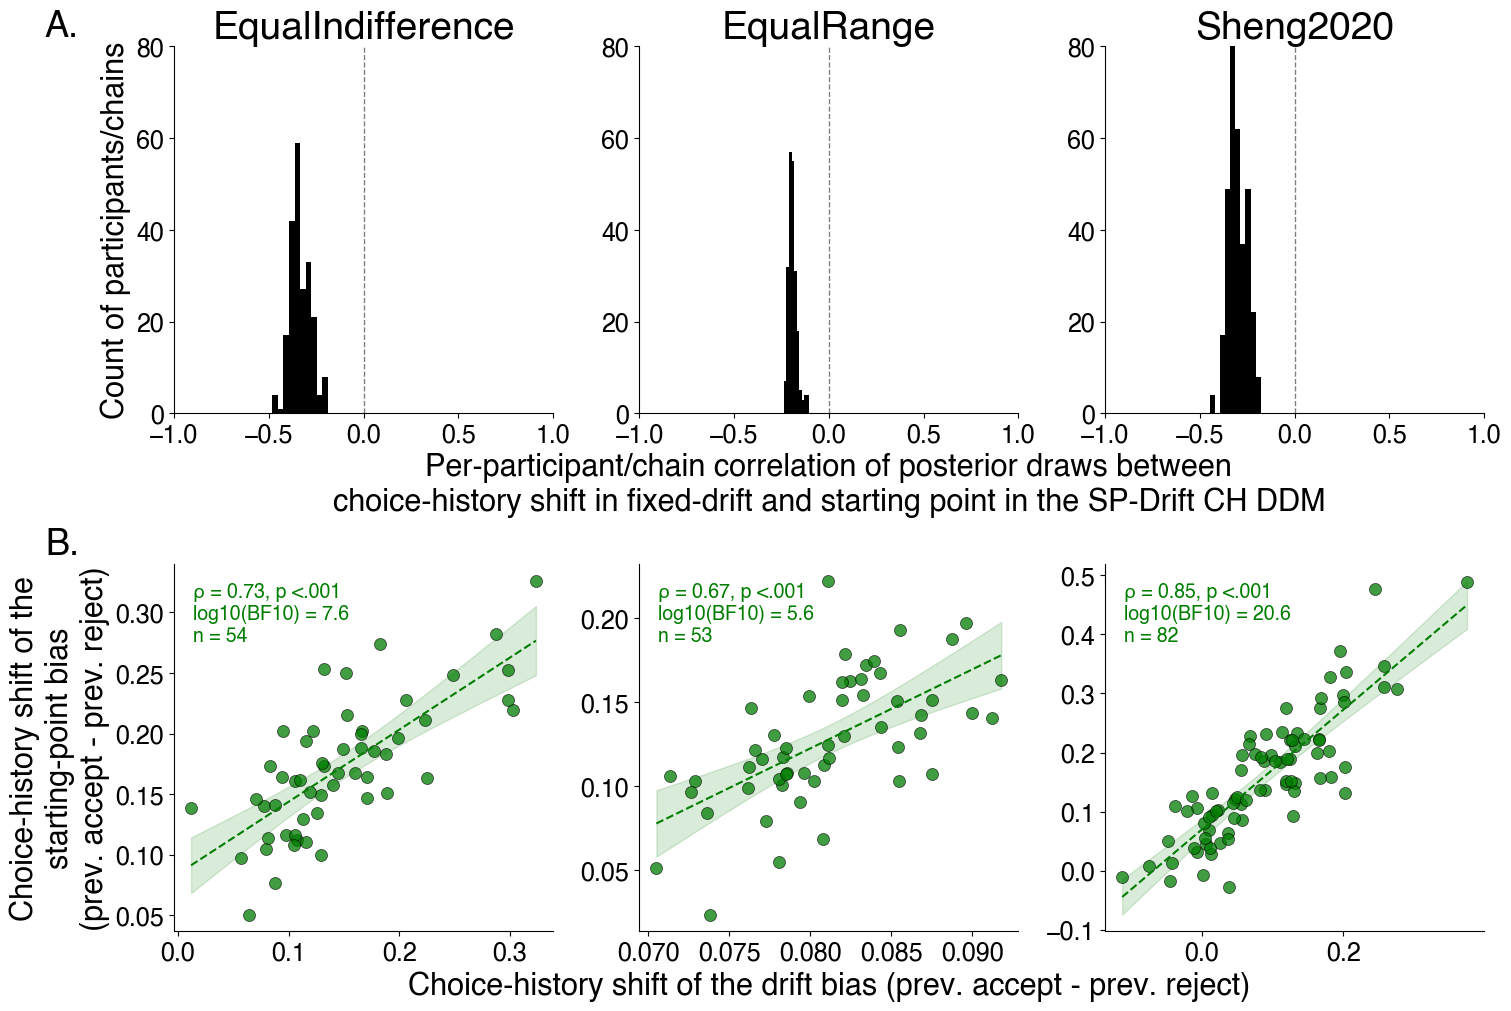

In [5]:
CORR_COLOR = "#000000"


def compute_subject_correlations(dataset):
    """Per-subject correlation between v_choice_prev1 and z_choice_prev1
    posterior draws (mean across chains), for the SP-Drift-CH model."""
    posterior = load_ddm_posterior(MODEL, dataset)
    subs = behavioral_data.query(f"dataset == '{dataset}'")["sub"].unique()

    correlations = []
    
    for sub in subs:
        v_key, z_key = f"v_choice_prev1_subj.{sub}", f"z_choice_prev1_subj.{sub}"
        if v_key not in posterior or z_key not in posterior:
            continue
        v_choice_prev1 = posterior[v_key]
        z_choice_prev1 = posterior[z_key]
        for chain in range(len(v_choice_prev1)):
            correlations.append(np.corrcoef(v_choice_prev1[chain], z_choice_prev1[chain])[0, 1])

    return np.array(correlations)


# --- Row B data: per-subject choice-history shift in fixed drift
# (v_choice_prev1) vs. starting point (z_choice_prev1), each from its own
# single-mechanism model ---
drift_vs_stp = {}

print("Individual shift in fixed drift (v_choice_prev1) vs. starting point (z_choice_prev1):")
for ds in DATASETS:
    stp_params = (load_ddm_subj_params(STP_DDM_MODEL, ds)
                 .pivot(index="sub", columns="param_name", values="param_value"))
    drift_params = (load_ddm_subj_params(DRIFT_DDM_MODEL, ds)
                    .pivot(index="sub", columns="param_name", values="param_value"))

    merged = pd.concat(
        [drift_params["v_choice_prev1"].rename("v_choice_prev1"),
         stp_params["z_choice_prev1"].rename("z_choice_prev1")],
        axis=1, join="inner",
    )
    exclude_ds = sorted(set(manual_exclusions_drift[ds]) | set(manual_exclusions_stp[ds]))
    merged = merged.drop(index=exclude_ds, errors="ignore")
    drift_vs_stp[ds] = merged

    result = spearman_corr_bf(merged["v_choice_prev1"].values, merged["z_choice_prev1"].values)
    print(f"  {ds}: r = {result['r']:.2f}, p = {result['pval']:.3g}, "
         f"log10(BF10) = {format_bf(result['bf10'])}, n = {result['n']}")


fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 10), layout="constrained")

print("\nPer-subject/chain posterior-draw correlation:")
for col, ds in enumerate(DATASETS):
    # --- Row A: posterior-draw correlation histogram ---
    ax = axes[0, col]
    correlations = compute_subject_correlations(ds)

    ax.hist(correlations, bins=10, color=CORR_COLOR, linewidth=0.5)
    ax.axvline(0, color="black", linestyle="--", linewidth=1, alpha=0.5)
    ax.set_xlim(-1, 1)
    ax.set_ylim(0, 80)
    ax.set_title(DATASET_LABELS.get(ds, ds))
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    print(f"  {ds}: mean = {correlations.mean():.3f}, sd = {correlations.std(ddof=1):.3f}, n = {len(correlations)}")
    print(f"  {ds}: min = {correlations.min():.3f}, max = {correlations.max():.3f}")

    # --- Row B: individual choice-history shift scatterplot ---
    merged = drift_vs_stp[ds]
    plot_spearman_corr(axes[1, col], merged["v_choice_prev1"].values, merged["z_choice_prev1"].values)
    style_axis(axes[1, col], col,
              ylabel="Choice-history shift of the\nstarting-point bias\n(prev. accept - prev. reject)",
              xlabel="Choice-history shift of the drift bias (prev. accept - prev. reject)")

axes[0, 0].set_ylabel("Count of participants/chains")
axes[0, 1].set_xlabel("Per-participant/chain correlation of posterior draws between\nchoice-history shift in fixed-drift and starting point in the SP-Drift CH DDM")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.25, 1.1, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.25, 1.1, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figureS6.svg", dpi=300, bbox_inches="tight")
plt.show()